In [47]:
from em1d.experiment import *
from em1d.transforms import invLaplace
import matplotlib.pyplot as plt
import numpy as np

class ForwardLaplace:
    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_gatewidth=None):
        self.source = source
        self.receiver = receiver
        self.times = times if isinstance(times, torch.Tensor) else torch.tensor(times)
        self.rmin = self.source.min_horizontal_distance(self.receiver).to(times.device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(times.device)
        self.dz = torch.tensor(self.receiver.z+self.source.z[0], device=times.device)
        self.waveform = waveform
        if t_gatewidth is not None:
            if isinstance(t_gatewidth, float): t_gatewidth = torch.ones_like(self.times)*t_gatewidth
            elif not isinstance(t_gatewidth, torch.Tensor) and t_gatewidth is not None: t_gatewidth = torch.tensor(t_gatewidth, device=self.times.device)
            self.t_gatewidth = t_gatewidth
            self.t_st = self.times-t_gatewidth/2
            self.t_end= self.times+t_gatewidth/2
        else:
            self.t_gatewidth=None
        if self.t_gatewidth is not None:
            self.tmin = (self.times-t_gatewidth/2).min()/1.1
            self.tmax = (self.times+t_gatewidth/2).max()
        else:
            self.tmin = self.times.min()
            self.tmax = self.times.max()

        self.filterfunc = filterfunc
        self.device = times.device
        if waveform is not None:
            if self.waveform.time.max()<self.tmin:
                self.tmin += -self.waveform.time.max()
            self.tmax += -self.waveform.time.min()
            waveform.time = waveform.time.to(self.device)
            waveform.amplitude = waveform.amplitude.to(self.device)
            waveform.d2wdt2 = waveform.d2wdt2.to(self.device)

    def forward(self):
        def wvlngth_integrand(wave_length):
            lmb = wave_length[None, :, None]

            def laplace_integrand(s):
                """ Hz from horizontal electric dipole. """
                omega = -1j*s
                tmp_u0 = u0(omega, lmb)
                intg = torch.exp(-tmp_u0*self.dz)*rte(self.sigma, self.thick, omega, lmb)*lmb**2 / tmp_u0
                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(omega)
                res = torch.squeeze(intg/c.fourpi)
                return res#.real
            
            cbft = invLaplace(laplace_integrand, n_coefficients=16)
            resp = cbft(self.times)
            return resp
        hkl1 = Hankel(wvlngth_integrand, 1, smp_per_decade=10, range=(self.rmin, self.rmax), device=self.device)
        return integrate_around_loop(self.source, self.receiver, hkl1).T
        

    def __call__(self, sigma, thickness):
        self.sigma = torch.tensor(sigma,     device=self.device, dtype=torch.complex128)[...,None,None]
        self.thick = torch.tensor(thickness, device=self.device, dtype=torch.complex128)[...,None,None]
        return self.forward().real*c.mu0

In [48]:
from em1d.transforms import hankel_coefficients
hk1 = hankel_coefficients(1, -20, 10, 10)

In [6]:
## tested performing the hankel first, followed by the invlaplace... takes way longer (~4x)

from em1d.experiment import *
from em1d.transforms import invLaplace
import matplotlib.pyplot as plt
import numpy as np

class ForwardLaplace:
    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_gatewidth=None):
        self.source = source
        self.receiver = receiver
        self.times = times if isinstance(times, torch.Tensor) else torch.tensor(times)
        self.rmin = self.source.min_horizontal_distance(self.receiver).to(times.device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(times.device)
        self.dz = torch.tensor(self.receiver.z+self.source.z[0], device=times.device)
        self.waveform = waveform
        if t_gatewidth is not None:
            if isinstance(t_gatewidth, float): t_gatewidth = torch.ones_like(self.times)*t_gatewidth
            elif not isinstance(t_gatewidth, torch.Tensor) and t_gatewidth is not None: t_gatewidth = torch.tensor(t_gatewidth, device=self.times.device)
            self.t_gatewidth = t_gatewidth
            self.t_st = self.times-t_gatewidth/2
            self.t_end= self.times+t_gatewidth/2
        else:
            self.t_gatewidth=None
        if self.t_gatewidth is not None:
            self.tmin = (self.times-t_gatewidth/2).min()/1.1
            self.tmax = (self.times+t_gatewidth/2).max()
        else:
            self.tmin = self.times.min()
            self.tmax = self.times.max()

        self.filterfunc = filterfunc
        self.device = times.device
        if waveform is not None:
            if self.waveform.time.max()<self.tmin:
                self.tmin += -self.waveform.time.max()
            self.tmax += -self.waveform.time.min()
            waveform.time = waveform.time.to(self.device)
            waveform.amplitude = waveform.amplitude.to(self.device)
            waveform.d2wdt2 = waveform.d2wdt2.to(self.device)

    def forward(self):
        
        def laplace_integrand(s):
            omega = -1j*s[None, :, None]
            def wvlngth_integrand(wave_length):
                lmb = wave_length[None, None, :]
                tmp_u0 = u0(omega, lmb)

                intg = torch.exp(-tmp_u0*self.dz)*rte(self.sigma, self.thick, omega, lmb)*lmb**2 / tmp_u0

                if self.waveform is not None:
                    intg /= -1j*omega

                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(omega)
                res = torch.squeeze(intg/c.fourpi)
                return res
            hkl1 = Hankel(wvlngth_integrand, 1, smp_per_decade=10, range=(self.rmin, self.rmax), device=self.device)
            return integrate_around_loop(self.source, self.receiver, hkl1)            
        cbft = invLaplace(laplace_integrand, n_coefficients=8)
        resp = cbft(self.times)
        return resp.T

        

    def __call__(self, sigma, thickness):
        self.sigma = torch.tensor(sigma,     device=self.device, dtype=torch.complex128)[...,None,None]
        self.thick = torch.tensor(thickness, device=self.device, dtype=torch.complex128)[...,None,None]
        return self.forward().real*c.mu0
    
# %%timeit
# dbdt2 = fwr2(sigma, thick)

In [7]:
class Forward:
    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_gatewidth=None, tolerance=None):
        self.source = source
        self.receiver = receiver
        self.times = times if isinstance(times, torch.Tensor) else torch.tensor(times)
        self.rmin = self.source.min_horizontal_distance(self.receiver).to(times.device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(times.device)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        self.rz = self.receiver.z
        self.pfield_dz = torch.abs(self.srcz-self.rz)
        self.sfield_dz = torch.abs(self.srcz)+torch.abs(self.rz)

        self.waveform = waveform
        if t_gatewidth is not None:
            if isinstance(t_gatewidth, float): t_gatewidth = torch.ones_like(self.times)*t_gatewidth
            elif not isinstance(t_gatewidth, torch.Tensor) and t_gatewidth is not None: t_gatewidth = torch.tensor(t_gatewidth, device=self.times.device)
            self.t_gatewidth = t_gatewidth
            self.t_st = self.times-t_gatewidth/2
            self.t_end= self.times+t_gatewidth/2
        else:
            self.t_gatewidth=None
        if self.t_gatewidth is not None:
            self.tmin = (self.times-t_gatewidth/2).min()/1.1
            self.tmax = (self.times+t_gatewidth/2).max()
        else:
            self.tmin = self.times.min()
            self.tmax = self.times.max()

        self.filterfunc = filterfunc
        self.device = times.device
        if waveform is not None:
            if self.waveform.time.max()<self.tmin:
                self.tmin += -self.waveform.time.max()
            self.tmax += -self.waveform.time.min()
            waveform.time = waveform.time.to(self.device)
            waveform.amplitude = waveform.amplitude.to(self.device)
            waveform.d2wdt2 = waveform.d2wdt2.to(self.device)
        self.tolerance=tolerance

    def forward(self):
        def wvlngth_integrand(wave_length):
            lmb = wave_length[None, :, None]
            def laplace_integrand(s):
                omega = -1j*s[None, None, :]
                tmp_u0 = u0(omega, lmb)
                intg = torch.exp(-tmp_u0*self.pfield_dz)+rte(self.sigma, self.thick, omega, lmb)*torch.exp(-tmp_u0*self.sfield_dz)
                intg *= lmb**2 / tmp_u0
                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(omega)
                return torch.squeeze(intg/c.fourpi)
            resp_t = invLaplace(laplace_integrand, n_coefficients=16, device=self.device, tolerance=self.tolerance)(self.times)

            hkl1 = Hankel(wvlngth_integrand, 1, range=(self.rmin, self.rmax), device=self.device, tolerance=self.tolerance)
            res = integrate_around_loop(self.source, self.receiver, hkl1)
            if self.waveform is not None:
                res /= -1j*omega.squeeze()
            return res
        
        cbft=invFourier(frq_integrand, smp_per_decade=16, range=(self.tmin, self.tmax), device=self.device, tolerance=self.tolerance)

        if self.t_gatewidth is None:
            t = self.times


        if self.waveform is not None:
            t_eval = t[:, None] - self.waveform.time[None, :]
            tshp = t_eval.shape
            t_eval = t_eval.reshape(-1)
            resp_step = cbft(t_eval).real.reshape(tshp)
            dbdt = resp_step @ self.waveform.d2wdt2
            if self.t_gatewidth is not None:
                cbft = CubicSpline(t, dbdt, transform=torch.log10)
            else:
                return dbdt
        if self.t_gatewidth is not None:
            return cbft.integrate(self.t_st, self.t_end, normalize=True)
        else:
            return cbft(self.times)


    def __call__(self, sigma, thickness):
        if isinstance(sigma, np.ndarray): sigma = torch.from_numpy(sigma)
        if isinstance(thickness, np.ndarray): thickness = torch.from_numpy(thickness)
        self.sigma = (sigma     + 0j).to(self.device)[...,None,None]
        self.thick = (thickness + 0j).to(self.device)[...,None,None]
        return self.forward().real*c.mu0

In [78]:
## tested performing the hankel first, followed by the invlaplace... takes way longer (~4x)

from em1d.experiment import *
from em1d.transforms import invLaplace
from em1d.physics import calc_wavenumber
import matplotlib.pyplot as plt
import numpy as np

from em1d.physics import hz_halfspace_center_circle_loop


class ForwardLaplaceHalfspace:
    def __init__(self, radius, times):
        self.radius = radius
        self.times = times if isinstance(times, torch.Tensor) else torch.tensor(times)
        self.times = self.times.to(torch.float64)

    def forward(self):
        def laplace_integrand(s):
            omega = -1j*s
            return hz_halfspace_center_circle_loop(self.sigma, omega, self.radius).real 
        cbft = invLaplace(laplace_integrand, n_coefficients=16) 
        resp = cbft(self.times)
        return resp.squeeze()     

    def __call__(self, sigma, thick):
        self.sigma = torch.tensor(sigma, dtype=torch.complex128)
        return self.forward().real

In [100]:
sigma = torch.tensor([1e-2, 1e-2], dtype=torch.complex128)[:, None, None]
thick = torch.tensor([40], dtype=torch.complex128)[:, None, None]

def frequency_response(sigma, thick, freq):
    omega = 2*np.pi*freq[None, :, None]
    
    def wvlngth_integrand(wave_length):
        """ Hz from horizontal electric dipole. """
        lmb = wave_length[None, None, :]
        tmp_u0 = u0(omega, lmb)
        cRTE = rte(sigma, thick, omega, lmb)
        intg = 1+cRTE
        intg *= lmb**2 / tmp_u0
        return torch.squeeze(intg/c.fourpi)

    hkl1 = Hankel(wvlngth_integrand, 1, smp_per_decade=10, range=(torch.tensor(25), torch.tensor(100)))
    return hkl1(50)*2*torch.pi*50

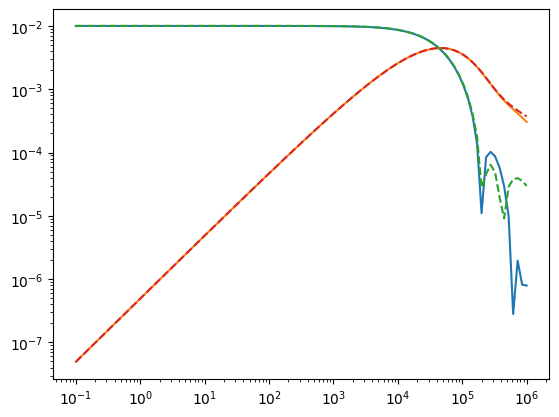

In [101]:
f = torch.logspace(-1, 6, 101, dtype=torch.float64)

hz = hz_halfspace_center_circle_loop(1/100, 2*np.pi*f, 50)
hz_num = frequency_response(sigma, thick, f)

plt.figure()
plt.loglog(f, abs(hz.real), label='real')
plt.loglog(f, abs(hz.imag), label='imag')

plt.loglog(f, abs(hz_num.real), '--', label='real')
plt.loglog(f, abs(hz_num.imag), '--', label='imag')

In [610]:
from em1d.transforms import gaver_stehfest_coefficients
class invLaplace:
    """ Inverse laplace transform using Gaver-Stehfest method.
        see https://dl.acm.org/doi/10.1145/361953.361969
        Algorithm 368: Numerical inversion of laplace transforms
    """
    def __init__(self, func, n_coefficients=8, device=None):
        #8 coefficient is more stable than 16 for current implementation. not sure why this is.

        assert n_coefficients % 2 == 0, "Gaver-stehfest method requires an even number of coefficients"
        self.func = func
        self.device = device
        self.v = gaver_stehfest_coefficients(n_coefficients)
        if device is not None:
            self.v = self.v.to(device)
        else:
            self.device = self.v.device
        self.i = torch.arange(n_coefficients)+1
        self.n_coefficients = n_coefficients
        

    def __call__(self, t):
        q = (c.log2 / t)
        iq = q[:, None]*self.i[None, :]
        f_eval = torch.einsum('ij,j->i', self.func(iq), self.v)
        return q*f_eval

In [645]:
class ForwardLaplaceHalfspace:
    def __init__(self, radius, times):
        self.radius = radius
        self.times = times if isinstance(times, torch.Tensor) else torch.tensor(times)
        self.times = self.times.to(torch.float64)

    def forward(self):
        def laplace_integrand(s):
            omega = -1j*s
            hz = hz_halfspace_center_circle_loop(self.sigma, omega, self.radius)
            return  (hz-(1./(2*self.radius)))/s
        cbft = invLaplace(laplace_integrand, n_coefficients=16)
        resp = cbft(self.times)
        return resp.squeeze()   

    def __call__(self, sigma, thick):
        self.sigma = torch.tensor(sigma, dtype=torch.complex128)
        return self.forward().real

In [646]:
t = torch.logspace(-7, -2, 51)
fwr2 = ForwardLaplaceHalfspace(50., t)

rho = 10
dbdt1 = fwr2(1/rho, None)

In [647]:
from em1d.physics import hzdt_halfspace_center_circle_loop
from em1d import constants as c

def hz_halfspace_center_circle_loop_time(times, sigma, r, I=1.):
    theta = tc.sqrt(0.25*c.mu0*sigma / times)
    theta_r = theta*r
    hz = 3*torch.exp(-theta_r**2)/(r*theta*c.sqrt_pi) + (1 - 3 / (2*theta_r**2))*tc.erf(theta_r)
    hz *= I/(2*r)
    return hz

In [648]:
dhzdt = hzdt_halfspace_center_circle_loop(t, 1./rho, 50)
hz = hz_halfspace_center_circle_loop_time(t, 1./rho, 50)

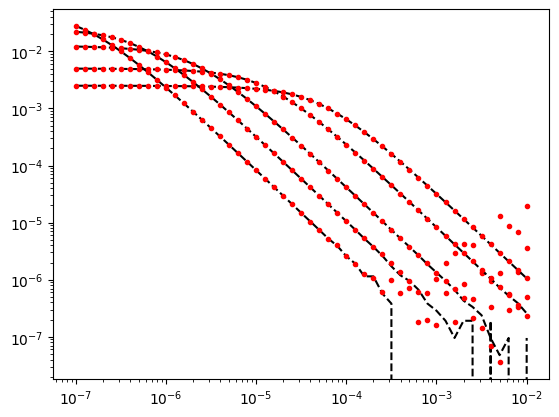

In [652]:
for rho in [10, 20, 40, 100, 200]:
    hz = hz_halfspace_center_circle_loop_time(t, 1./100, rho)
    fwr2 = ForwardLaplaceHalfspace(rho, t)

    hz_num = fwr2(1./100, None)
    plt.loglog(t, hz, 'k--', label=f'{rho}')
    plt.loglog(t, np.abs(hz_num.numpy()), 'r.', label=f'{rho}')

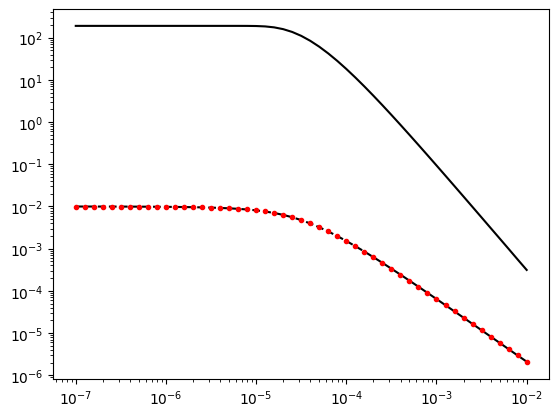

In [641]:
plt.figure()
plt.loglog(fwr2.times, abs(dhzdt.numpy()), 'k-')
plt.loglog(fwr2.times, abs(hz.numpy()), 'k--')
plt.loglog(fwr2.times, abs(dbdt1.numpy()), 'r.')


In [51]:

nf = 10
sigma = torch.tensor([0.1, 1, 0.1, 0.3, 10, 25, 0.2, 0.5, 10, 15, 20])[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]
thick = torch.tensor([40, 40, 40, 40, 40, 40, 40, 40, 40, 40])[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]
source = Loop.square(50)
receiver = Receiver()
wv = Waveform.example()
fwr1 = ForwardLaplace(source, receiver, t.to(torch.float64), waveform=wv)

dbdt1 = fwr1(sigma, thick)
dbdt2 = fwr2(1./40, None)

c:\users\au646858\onedrive - aarhus universitet\documents\repositories\em1d\src\em1d\experiment\experiment.py:105: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return tc.tensor(overall_min)
C:\Users\au646858\AppData\Local\Temp\ipykernel_30328\1734540243.py:13: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.dz = torch.tensor(self.receiver.z+self.source.z[0], device=times.device)
C:\Users\au646858\AppData\Local\Temp\ipykernel_30328\1734540243.py:62: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.sigma = torch.tensor(sigma,     devi

t_shape:  torch.Size([51])
f_eval_shape:  torch.Size([10, 301, 16])
res1 shape:  torch.Size([10, 301])
res shape:  torch.Size([51])


RuntimeError: expand(CPUComplexDoubleType{[10, 301]}, size=[]): the number of sizes provided (0) must be greater or equal to the number of dimensions in the tensor (2)

NameError: name 'dbdt2' is not defined

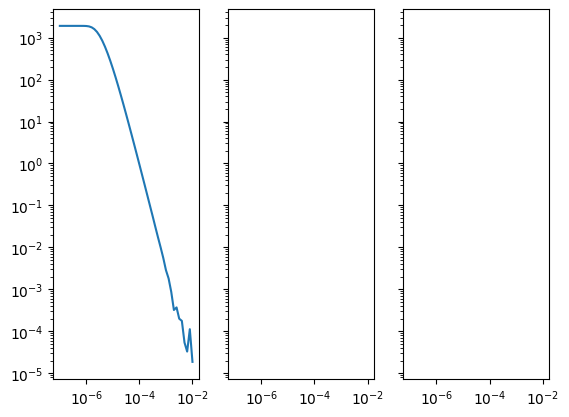

In [52]:
fig,axs = plt.subplots(1,3, sharex=True, sharey=True)
axs[0].loglog(fwr1.times.numpy(), np.abs(dbdt1.real.numpy().T))
axs[1].loglog(fwr1.times.numpy(), np.abs(dbdt2.real.numpy()).T, '--')
axs[2].loglog(fwr1.times.numpy(), np.abs(dbdt1.real[0].numpy()))
axs[2].loglog(fwr1.times.numpy(), np.abs(dbdt2.real[0].numpy()), 'C0--')

axs[2].loglog(fwr1.times.numpy(), np.abs(dbdt1.real[1].numpy()))
axs[2].loglog(fwr1.times.numpy(), np.abs(dbdt2.real[0].numpy()), 'C1--')

t_shape:  torch.Size([31])
f_eval_shape:  torch.Size([16])
res1 shape:  torch.Size([1])
res shape:  torch.Size([31])
True


c:\Users\au646858\Miniconda3\envs\em1d\Lib\site-packages\matplotlib\cbook.py:1699: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\au646858\Miniconda3\envs\em1d\Lib\site-packages\matplotlib\cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


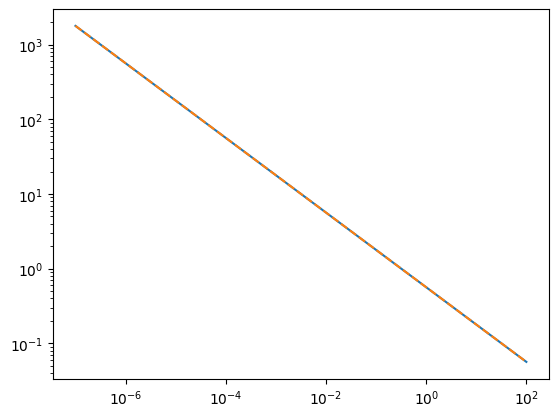

In [53]:
def f(t):
    return 1./torch.sqrt(torch.pi*t)

def LF(s):
    return 1./torch.sqrt(s)

t = torch.logspace(-7, 2, 31, dtype=torch.complex128)

f_est = invLaplace(LF, n_coefficients=16)(t)
f_act = f(t)

print(torch.allclose(f_est.real, f_act.real))

plt.figure()
plt.loglog(t.numpy(), f_est.numpy())
plt.loglog(t.numpy(), f_act.numpy(), '--')